In [79]:
%load_ext autoreload
%autoreload 2

import numpy as np
from functools import partial 
import torch
from torch.optim import Adam
from tqdm.notebook import trange,tqdm
import matplotlib.pyplot as plt
from torch.utils.data import (
    DataLoader,
    Dataset,
    Subset,
)
from torchvision import datasets
from torchvision.transforms import ToTensor



from score_model import ScoreNet
from score_model_generation import ConditionalScoreNet

import diffusion_process as dfp

from diffusion_model import DiffusionModel


from diffusion_utilities import (
    plot_image_grid,
    plot_image_evolution,
    animation_images,
)
from integrators import (
    euler_maruyama as eu, 
    predictor_corrector as pc,
    probability_flow_ode as pfo
    )

from quality import (
    bpd,
    fid
)

from generation.class_conditioning_sampling import conditional_loss_function
from generation.em_imputation import *

device = 'cuda' if torch.cuda.is_available() else 'cpu'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Variance Exploding (VE)

In [80]:
ve_exponential = DiffusionModel(
    type="VE",
    sigma=25.0,
)

sigma_t_ve = ve_exponential.sigma_t
diffusion_ve = ve_exponential.diffusion

In [81]:
#Create the net
#from score_model_rgb import ScoreNet
score_model = torch.nn.DataParallel(ScoreNet(marginal_prob_std=sigma_t_ve))
score_model.to(device)

#Load the trained model
score_model.load_state_dict(torch.load("trained_models/ve.pth", map_location=device))
score_model.eval()

#Initial Noise
n_images = 100
n_images_smaller = 5
T = 1.0

#VP
image_T = torch.randn(n_images, 1, 28, 28, device=device)



- Euler-Maruyama integrator

In [82]:
drift_backward_ve = ve_exponential.get_backward_drift(score_model)
with torch.no_grad():
    times, synthetic_images_t = eu.euler_maruyama_integrator(
        image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_ve,
        diffusion_coefficient=ve_exponential.diffusion,
    )

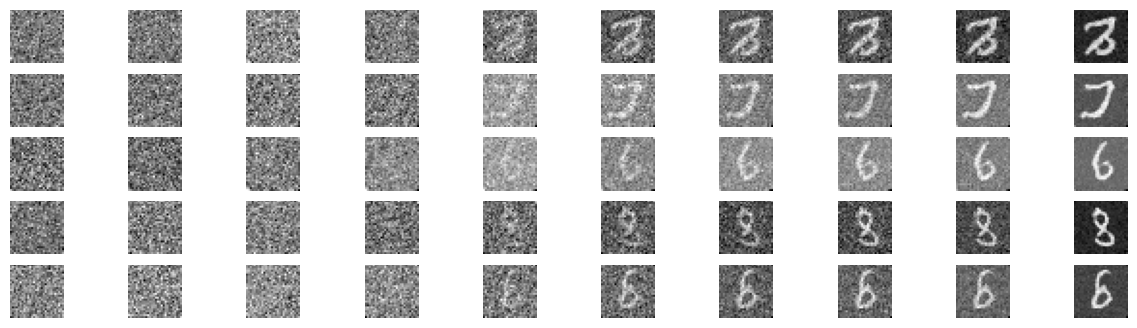

In [83]:
#Plot results
_ = plot_image_evolution(
    images=synthetic_images_t[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- Predictor Corrector

In [84]:
with torch.no_grad():
    times, synthetic_images_t_pc = pc.predictor_corrector_integrator(
        x_0=image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        backward_drift_coefficient=drift_backward_ve,
        diffusion_coefficient=ve_exponential.diffusion,
        score_model=score_model,
        corrector_steps=1,
        corrector_step_size=1e-4,
        normalize_score=False,
    )

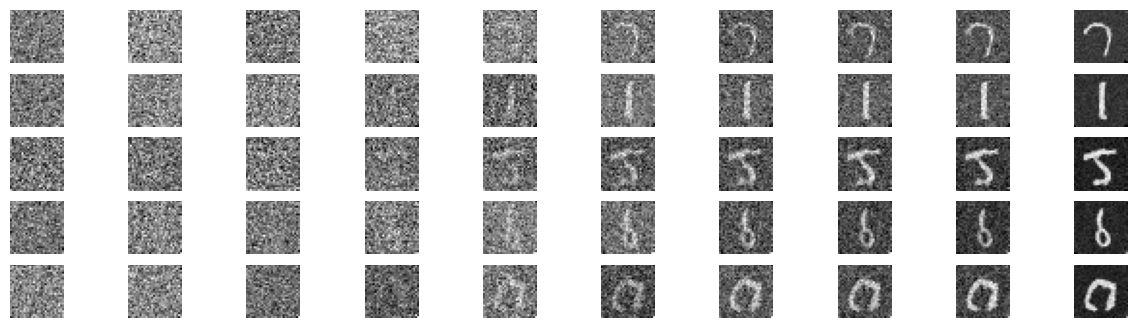

In [85]:
#Plot results
_ = plot_image_evolution(
    images=synthetic_images_t_pc.detach().cpu()[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- Probability Flow ODE

In [86]:
ode_drift_ve = ve_exponential.get_probability_flow_drift(score_model)
with torch.no_grad():
    times_ode, synthetic_images_t_ode = pfo.probability_flow_ode_integrator(
        x_0=image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        ode_drift_coefficient=ode_drift_ve,
    )

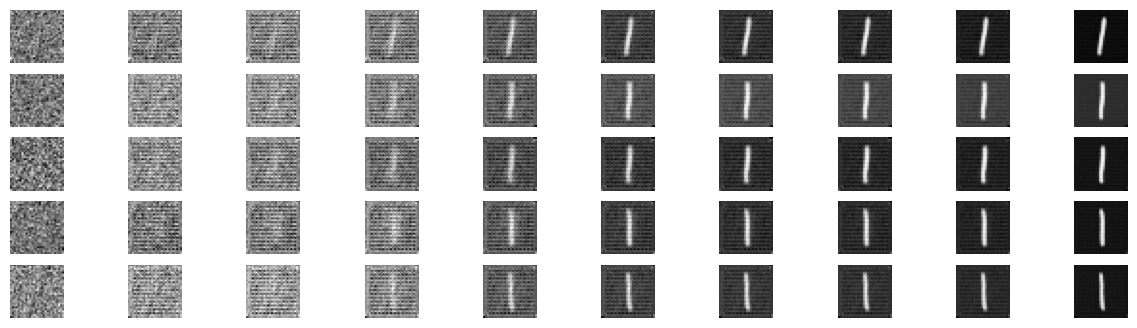

In [87]:
_ = plot_image_evolution(
    images=synthetic_images_t_ode[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

## Variance Preserving (VP)

#### 1. Linear

In [88]:

vp_linear = DiffusionModel(
    type="VP",
    schedule="linear",
    beta_min=0.1,
    beta_max=20.0,
)

In [89]:
#Create the net
score_model_vp_linear = ScoreNet(marginal_prob_std=vp_linear.sigma_t)
score_model_vp_linear.to(device)

#Load the trained model
score_model_vp_linear.load_state_dict(torch.load("trained_models/vp_linear.pth", map_location=device))
_ = score_model_vp_linear.eval()

- Euler-Maruyama integrator

In [90]:
drift_backward_vp_linear = vp_linear.get_backward_drift(score_model_vp_linear)
with torch.no_grad():
    times_vp_linear, synthetic_images_t_vp_linear = eu.euler_maruyama_integrator(
        image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_vp_linear,
        diffusion_coefficient=vp_linear.diffusion,
    )

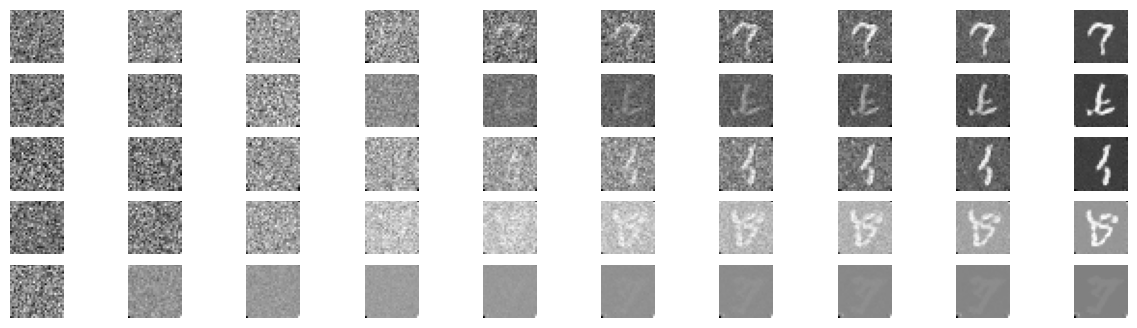

In [91]:
#Plot results
_ = plot_image_evolution(
    images=synthetic_images_t_vp_linear[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- Predictor Corrector

In [92]:
with torch.no_grad():
    times, synthetic_images_t_pc_vp_linear = pc.predictor_corrector_integrator(
        x_0=image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        backward_drift_coefficient=drift_backward_vp_linear,
        diffusion_coefficient=vp_linear.diffusion ,
        score_model=score_model_vp_linear,
        corrector_steps=1,
        corrector_step_size=1e-4,
        normalize_score=False,
    )

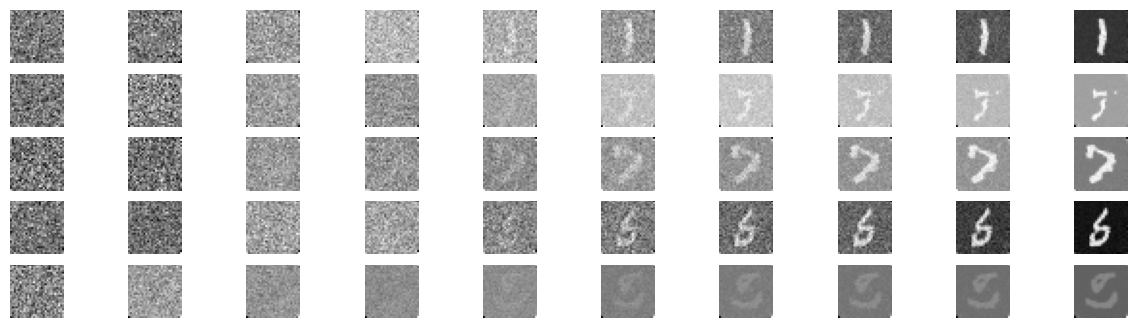

In [93]:
#Plot results
_ = plot_image_evolution(
    images=synthetic_images_t_pc_vp_linear.detach().cpu()[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- Probability Flow ODE

In [94]:
ode_drift_vp_linear = vp_linear.get_probability_flow_drift(score_model_vp_linear)
with torch.no_grad():
    times_ode, synthetic_images_t_ode_vp_linear = pfo.probability_flow_ode_integrator(
        x_0=image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=2000,
        ode_drift_coefficient=ode_drift_vp_linear,
    )

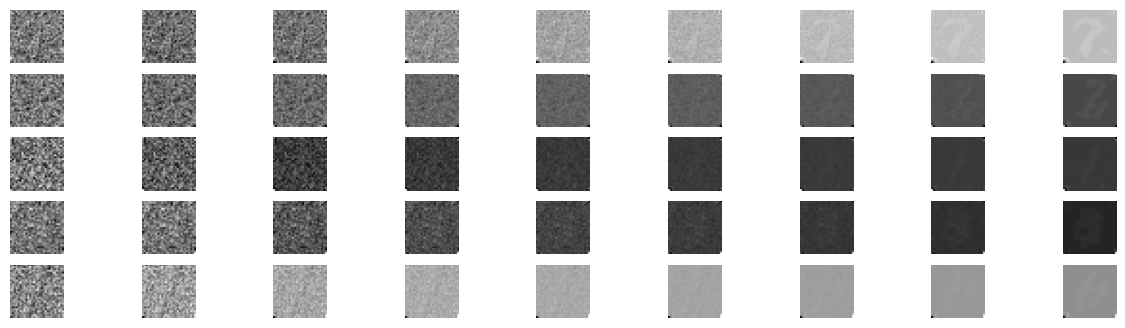

In [95]:
_ = plot_image_evolution(
    images=synthetic_images_t_ode_vp_linear[:5],
    n_images=5,
    n_intermediate_steps=np.linspace(0, 2000, 9, dtype=int),
    figsize=(15, 4),
)

#### 2. Cosine 

In [96]:
vp_cosine = DiffusionModel(
    type="VP",
    schedule="cosine",
    s=0.008,
)

sigma_t_cosinep = vp_cosine.sigma_t
diffusion_cosinep = vp_cosine.diffusion

In [97]:
#Create the net
score_model_vp_cosine = torch.nn.DataParallel(ScoreNet(marginal_prob_std=sigma_t_cosinep))
score_model_vp_cosine.to(device)

#Load the trained model
score_model_vp_cosine.load_state_dict(torch.load("trained_models/vp_cosine.pth", map_location=device))
_ = score_model_vp_cosine.eval()

- Euler-Maruyama integrator

In [98]:
drift_backward_vp_cosine = vp_cosine.get_backward_drift(score_model_vp_cosine)
T = 1.0 - 1e-3 #so it doesn't explode around one
with torch.no_grad():
    times_vp_cosine, synthetic_images_t_vp_cosine= eu.euler_maruyama_integrator(
        image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_vp_cosine,
        diffusion_coefficient=vp_cosine.diffusion,
    )

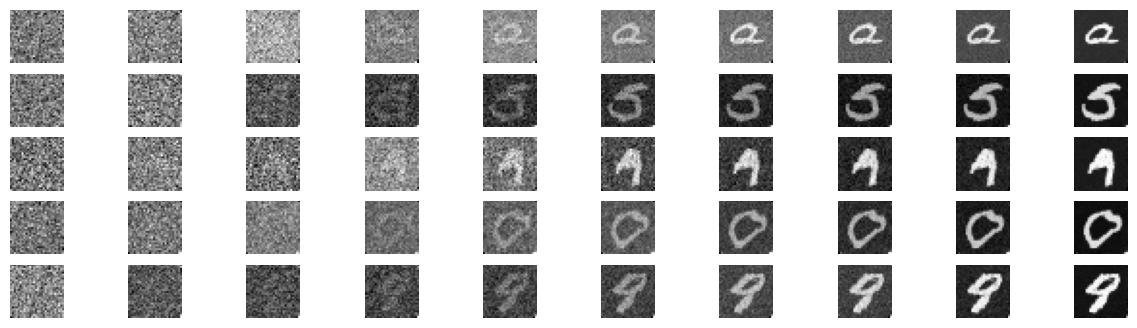

In [99]:
#Plot results
_ = plot_image_evolution(
    images=synthetic_images_t_vp_cosine[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- Predictor Corrector

In [100]:
with torch.no_grad():
    times, synthetic_images_t_pc_vp_cosine = pc.predictor_corrector_integrator(
        x_0=image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        backward_drift_coefficient=drift_backward_vp_cosine,
        diffusion_coefficient=diffusion_cosinep ,
        score_model=score_model_vp_cosine,
        corrector_steps=1,
        corrector_step_size=1.0e-4,
        normalize_score=False,
    )

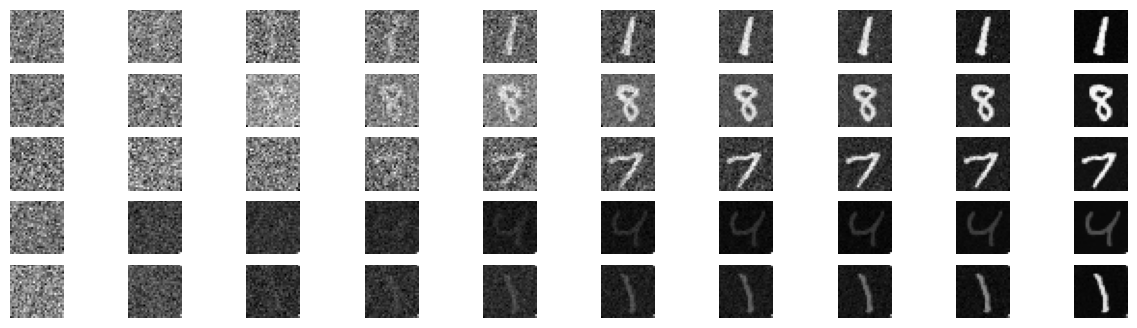

In [101]:
#Plot results
_ = plot_image_evolution(
    images=synthetic_images_t_pc_vp_cosine.detach().cpu()[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- Probability Flow ODE

In [120]:
ode_drift_vp_cosine = vp_cosine.get_probability_flow_drift(score_model_vp_cosine)
with torch.no_grad():
    times_ode, synthetic_images_t_ode_vp_cosine = pfo.probability_flow_ode_integrator(
        x_0=image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        ode_drift_coefficient=ode_drift_vp_cosine,
    )

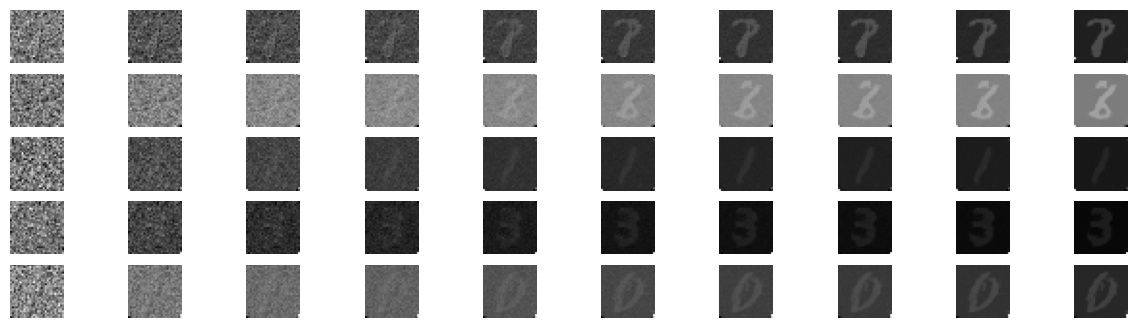

In [121]:
_ = plot_image_evolution(
    images=synthetic_images_t_ode_vp_cosine[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

## Measure Quality

## **BPD**

In [104]:
#Load dataset for to evaluate the model using the real images
batch_size = 128

data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)
data_train = data
data_loader = DataLoader(
    data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)
#we take a batch
x_real, _ = next(iter(data_loader))
x_real = x_real.to(device)

- VE

In [105]:
logp0_ve_linear, bpd_ve = bpd.bpd_batch_probability_flow(
    score_model=score_model,
    diffusion_model=ve_exponential,
    x0=x_real,
    t_start=1e-3,
    t_end=1.0,
    n_steps=500,
    noise_type="rademacher",
)

print("Mean batch BPD:", bpd_ve.mean().item())
print("Std batch BPD:", bpd_ve.std().item())

Mean batch BPD: 4.457427024841309
Std batch BPD: 0.19766294956207275


- VP - linear

In [106]:
logp0_vp_linear, bpd_vp_linear = bpd.bpd_batch_probability_flow(
    score_model=score_model_vp_linear,
    diffusion_model=vp_linear,
    x0=x_real,
    t_start=1e-3,
    t_end=1.0,
    n_steps=500,
    noise_type="rademacher",
)

print("Mean batch BPD:", bpd_vp_linear.mean().item())
print("Std batch BPD:", bpd_vp_linear.std().item())

Mean batch BPD: 4.873464584350586
Std batch BPD: 0.6386064887046814


- VP - cosine

In [107]:
logp0_vp_cosine, bpd_vp_cosine = bpd.bpd_batch_probability_flow(
    score_model=score_model_vp_cosine,
    diffusion_model=vp_cosine,
    x0=x_real,
    t_start=1e-3,
    t_end=1.0,
    n_steps=500,
    noise_type="rademacher",
)

print("Mean batch BPD:", bpd_vp_cosine.mean().item())
print("Std batch BPD:", bpd_vp_cosine.std().item())

Mean batch BPD: 2.306222677230835
Std batch BPD: 0.3723200559616089


## **FID**

In [108]:
#We begin preparing the dataset for FID
#We transform the datset to have 3 canals (RGB)
from quality.fid import rescale
from torchmetrics.image.fid import FrechetInceptionDistance #FID

**VE**
- Euler-Maruyama integrator

In [109]:
fid = FrechetInceptionDistance(feature=2048).to(device)
fid.reset()

#pass to the inception net the same number of images that we have generated
generated_images = synthetic_images_t[..., -1]
generated_images = torch.clamp(generated_images, 0.0, 1.0)
num_gen_images = generated_images.shape[0]


x_real, _ = next(iter(data_loader))
x_real = x_real.to(device)

#keep the same number of real images as generated images
x_real = x_real[:num_gen_images]

x_real_fid = rescale(x_real)#resclae the real images

#update FID with real images
fid.update(x_real_fid, real=True)

In [110]:
generated_images_fid = rescale(generated_images)#prepre our synthetic images for FID
fid.update(generated_images_fid, real=False)

fid_score = fid.compute()
print("FID:", fid_score.item())

FID: 170.01878356933594


**VP - linear**
- Predictor Corrector

In [111]:
#new FID object
fid_pc = FrechetInceptionDistance(feature=2048).to(device)
fid_pc.reset()

#VP Predictor-Corrector generated images
generated_images_pc_vp_linear = synthetic_images_t_pc_vp_linear[..., -1]
generated_images_pc_vp_linear = torch.clamp(generated_images_pc_vp_linear, 0.0, 1.0)


num_gen_images_pc_linear = generated_images_pc_vp_linear.shape[0]

x_real, _ = next(iter(data_loader))
x_real = x_real.to(device)
x_real = x_real[:num_gen_images_pc_linear]

#prepare and update real images
x_real_fid_pc = rescale(x_real)
fid_pc.update(x_real_fid_pc, real=True)

#prepare and update generated images
generated_images_fid_pc_linear = rescale(generated_images_pc_vp_linear)
fid_pc.update(generated_images_fid_pc_linear, real=False)

#Compute FID
fid_score_pc_linear = fid_pc.compute()
print("FID VP linear:", fid_score_pc_linear.item())

FID VP linear: 176.12220764160156


**VP - cosine**
- Euler-Maruyama integrator

In [112]:
fid_vpc = FrechetInceptionDistance(feature=2048).to(device)
fid_vpc.reset()


generated_images_vp_cosine = synthetic_images_t_vp_cosine[..., -1]
generated_images_vp_cosine = torch.clamp(generated_images_vp_cosine, 0.0, 1.0)


num_gen_images_cosine = generated_images_vp_cosine.shape[0]

x_real, _ = next(iter(data_loader))
x_real = x_real.to(device)
x_real = x_real[:num_gen_images_cosine]


x_real_fid_vpc = rescale(x_real)
fid_vpc.update(x_real_fid_vpc, real=True)


generated_images_fid_cosine = rescale(generated_images_vp_cosine)
fid_vpc.update(generated_images_fid_cosine, real=False)


fid_score_vpc= fid_vpc.compute()
print("FID VP cosine:", fid_score_vpc.item())

FID VP cosine: 97.3110122680664


- IS

In [113]:
from torchmetrics.image.inception import InceptionScore

**VE**

In [114]:
is_metric = InceptionScore(splits=5).to(device)
is_metric.reset()

# Final generated images
generated_images = synthetic_images_t[..., -1]
generated_images = torch.clamp(generated_images, 0.0, 1.0)

# Prepare synthetic images for IS
generated_images_is = rescale(generated_images)

# Update IS with generated images
is_metric.update(generated_images_is)

# Compute IS
is_mean, is_std = is_metric.compute()
print("IS:", is_mean.item())
print("IS std:", is_std.item())

c:\Users\jimen\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


IS: 1.9527337551116943
IS std: 0.25102782249450684


**VP - linear**

In [115]:
is_metric_pc = InceptionScore(splits=5).to(device)
is_metric_pc.reset()

# VP Predictor-Corrector generated images
generated_images_pc_vp_linear = synthetic_images_t_pc_vp_linear[..., -1]
generated_images_pc_vp_linear = torch.clamp(generated_images_pc_vp_linear, 0.0, 1.0)

# Prepare synthetic images for IS
generated_images_is_pc_linear = rescale(generated_images_pc_vp_linear)

# Update IS with generated images
is_metric_pc.update(generated_images_is_pc_linear)

# Compute IS
is_mean_pc_linear, is_std_pc_linear = is_metric_pc.compute()
print("IS VP linear:", is_mean_pc_linear.item())
print("IS VP linear std:", is_std_pc_linear.item())

IS VP linear: 1.766379714012146
IS VP linear std: 0.09489461034536362


**VP - cosine**

In [116]:
is_metric_vpc = InceptionScore(splits=5).to(device)
is_metric_vpc.reset()

# VP cosine generated images
generated_images_vp_cosine = synthetic_images_t_vp_cosine[..., -1]
generated_images_vp_cosine = torch.clamp(generated_images_vp_cosine, 0.0, 1.0)

# Prepare synthetic images for IS
generated_images_is_cosine = rescale(generated_images_vp_cosine)

# Update IS with generated images
is_metric_vpc.update(generated_images_is_cosine)

# Compute IS
is_mean_vpc, is_std_vpc = is_metric_vpc.compute()
print("IS VP cosine:", is_mean_vpc.item())
print("IS VP cosine std:", is_std_vpc.item())

IS VP cosine: 1.7570722103118896
IS VP cosine std: 0.266732782125473


## Controllable generation

### **Class-conditional sampling**

In [122]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
score_model_cond = torch.nn.DataParallel(
    ConditionalScoreNet(marginal_prob_std=sigma_t_ve, n_classes=10)
).to(device)

optimizer = Adam(score_model_cond.parameters(), lr=1e-4)
n_epochs = 20
tqdm_epoch = trange(n_epochs)

for epoch in tqdm_epoch:
    score_model_cond.train()
    avg_loss = 0.0
    num_items = 0

    for x, y in data_loader:
        x = x.to(device)
        y = y.to(device).long()

        loss = conditional_loss_function(
            diffusion_process=ve_exponential,
            score_model=score_model_cond,
            x_0=x,
            y=y,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        avg_loss += loss.item() * x.shape[0]
        num_items += x.shape[0]

    tqdm_epoch.set_description('Average Loss: {:5f}'.format(avg_loss / num_items))

  0%|          | 0/20 [00:00<?, ?it/s]

- VE 

In [124]:

score_model_cond.eval()

T = 1.0

#we only evaluate class 3
y_cond = torch.full((n_images,), 3, device=device, dtype=torch.long)

drift_backward_ve_linear_cond = lambda x_t, t: -(
    ve_exponential.diffusion(t) ** 2
)[:, None, None, None] * score_model_cond(x_t, t, y_cond)


with torch.no_grad():
    times, synthetic_images_t_cg_ve_linear = eu.euler_maruyama_integrator(
        image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_ve_linear_cond,
        diffusion_coefficient=ve_exponential.diffusion,
    )

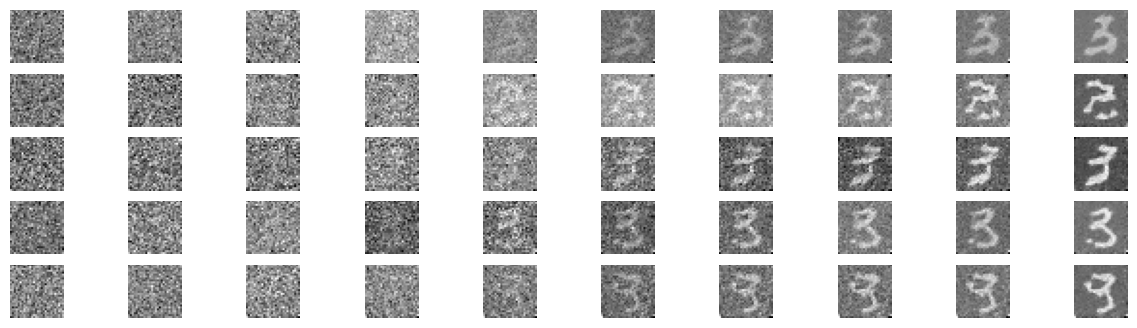

In [125]:
_ = plot_image_evolution(
    images=synthetic_images_t_cg_ve_linear[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- VP-linear

In [126]:
#conditional score model for VP linear
score_model_cond_vp_linear = torch.nn.DataParallel(
    ConditionalScoreNet(marginal_prob_std=vp_linear.sigma_t, n_classes=10)
).to(device)

optimizer = Adam(score_model_cond_vp_linear.parameters(), lr=1e-4)
n_epochs = 20
tqdm_epoch = trange(n_epochs)

for epoch in tqdm_epoch:
    score_model_cond_vp_linear.train()
    avg_loss = 0.0
    num_items = 0

    for x, y in data_loader:
        x = x.to(device)
        y = y.to(device).long()

        loss = conditional_loss_function(
            diffusion_process=vp_linear,
            score_model=score_model_cond_vp_linear,
            x_0=x,
            y=y,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        avg_loss += loss.item() * x.shape[0]
        num_items += x.shape[0]

    tqdm_epoch.set_description(
        'Average Loss: {:5f}'.format(avg_loss / num_items)
    )


  0%|          | 0/20 [00:00<?, ?it/s]

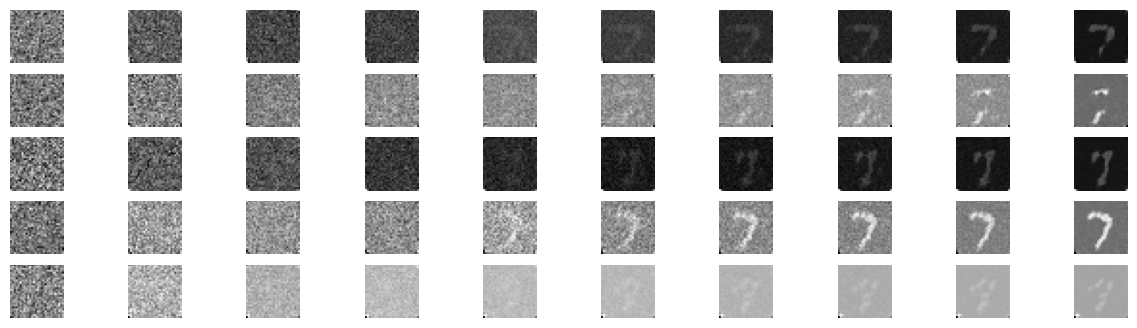

In [127]:
#sampling
score_model_cond_vp_linear.eval()

#condition on digit 7
y_cond = torch.full((n_images,), 7, device=device, dtype=torch.long)

drift_backward_vp_linear_cond = lambda x_t, t: (
    -0.5 * vp_linear.noise_schedule.beta_t_vp(t)[:, None, None, None] * x_t
    - (vp_linear.diffusion(t) ** 2)[:, None, None, None]
      * score_model_cond_vp_linear(x_t, t, y_cond)
)

with torch.no_grad():
    times, synthetic_images_t_cg_vp_linear = eu.euler_maruyama_integrator(
        image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_vp_linear_cond,
        diffusion_coefficient=vp_linear.diffusion,
    )

_ = plot_image_evolution(
    images=synthetic_images_t_cg_vp_linear[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

- VP - cosine

In [128]:
score_model_cond_vp_cosine = torch.nn.DataParallel(
    ConditionalScoreNet(marginal_prob_std=vp_cosine.sigma_t, n_classes=10)
).to(device)

optimizer = Adam(score_model_cond_vp_cosine.parameters(), lr=1e-4)
n_epochs = 20
tqdm_epoch = trange(n_epochs)

for epoch in tqdm_epoch:
    score_model_cond_vp_cosine.train()
    avg_loss = 0.0
    num_items = 0

    for x, y in data_loader:
        x = x.to(device)
        y = y.to(device).long()

        loss = conditional_loss_function(
            diffusion_process=vp_cosine,
            score_model=score_model_cond_vp_cosine,
            x_0=x,
            y=y,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        avg_loss += loss.item() * x.shape[0]
        num_items += x.shape[0]

    tqdm_epoch.set_description(
        'Average Loss: {:5f}'.format(avg_loss / num_items)
    )

  0%|          | 0/20 [00:00<?, ?it/s]

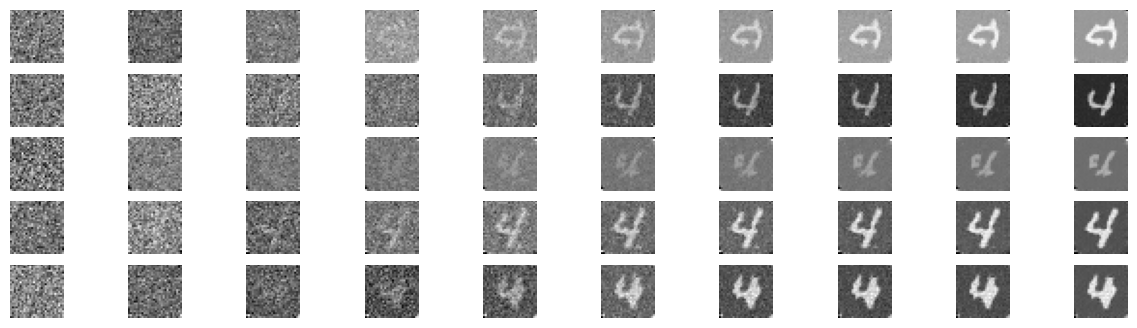

In [129]:
score_model_cond_vp_cosine.eval()

T = 1.0 - 1.0e-3

#condition on digit 4
y_cond = torch.full((n_images,), 4, device=device, dtype=torch.long)

drift_backward_vp_cosine_cond = lambda x_t, t: (
    -0.5 * vp_cosine.noise_schedule.beta_t_vp(t)[:, None, None, None] * x_t
    - (vp_cosine.diffusion(t) ** 2)[:, None, None, None]
      * score_model_cond_vp_cosine(x_t, t, y_cond)
)

with torch.no_grad():
    times, synthetic_images_t_cg_vp_cosine = eu.euler_maruyama_integrator(
        image_T,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_vp_cosine_cond,
        diffusion_coefficient=vp_cosine.diffusion,
    )

_ = plot_image_evolution(
    images=synthetic_images_t_cg_vp_cosine[:5],
    n_images=5,
    n_intermediate_steps=[0, 100, 200, 300, 400, 450, 470, 480, 490, 500],
    figsize=(15, 4),
)

### **Imputation**

Apply a mask to generate the images we want to imputate

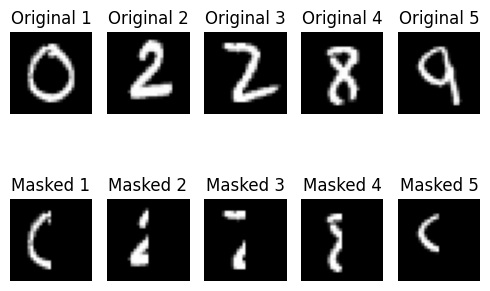

In [130]:
x_obs, _ = next(iter(data_loader))
x_obs = x_obs.to(device)[:5]

mask = right_half_mask(x_obs)
x_masked = mask * x_obs
x_masked = mask * x_obs #we apply the mask to generate the images we want to imputate

x_obs_cpu = x_obs.detach().cpu()
x_masked_cpu = x_masked.detach().cpu()

fig, axes = plt.subplots(2, 5, figsize=(5, 4))

for i in range(5):
    #original images
    axes[0, i].imshow(x_obs_cpu[i, 0], cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Original {i+1}")

    #masked image
    axes[1, i].imshow(x_masked_cpu[i, 0], cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title(f"Masked {i+1}")

plt.tight_layout()
plt.show()

- Euler-Maruyama

In [140]:
T = 1
image_T_ve_imputation =  torch.randn(5, 1, 28, 28, device=device)

with torch.no_grad():
    times_imp, imputed_images_t = euler_maruyama_imputation(
        x_0=image_T_ve_imputation,
        x_obs=x_obs,
        mask=mask,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        drift_coefficient=drift_backward_ve,
        diffusion_coefficient=ve_exponential.diffusion,
        mu_t=ve_exponential.mu_t,
        sigma_t=ve_exponential.sigma_t,
    )

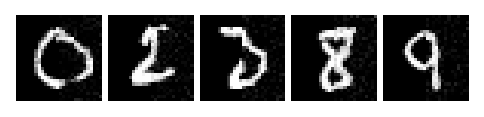

In [141]:
x_imputed = imputed_images_t[..., -1]
x_imputed = torch.clamp(x_imputed, 0.0, 1.0)

_ = plot_image_grid(
    images=x_imputed,
    figsize=(6, 6),
    n_rows=1,
    n_cols=n_images_smaller,
    normalize=True,
)

- Predictor-Corrector

In [150]:
image_T_vp_imputation = torch.randn(5, 1, 28, 28, device=device)
with torch.no_grad():
    times_imp_pc, imputed_images_vpl_pc = predictor_corrector_imputation(
        x_0=image_T_vp_imputation,
        x_obs=x_obs,
        mask=mask,
        t_0=T,
        t_end=1.0e-3,
        n_steps=500,
        backward_drift_coefficient=drift_backward_vp_linear,
        diffusion_coefficient=vp_linear.diffusion,
        score_model=score_model_vp_linear,
        mu_t=vp_linear.mu_t,
        sigma_t=vp_linear.sigma_t,
        corrector_steps=1,
        corrector_step_size=1e-4,
        normalize_score=True,
    )

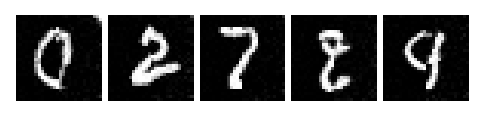

In [151]:
x_imputed_pc = torch.clamp(imputed_images_vpl_pc[..., -1], 0.0, 1.0)
_ = plot_image_grid(
    images=x_imputed_pc,
    figsize=(6, 6),
    n_rows=1,
    n_cols=n_images_smaller,
    normalize=True,
)

- Probability Flow ODE

In [156]:
T = 1- 1.0e-3
with torch.no_grad():
    times_imp_ode, imputed_images_t_ode_vp = probability_flow_ode_imputation(
        x_0=image_T_vp_imputation,
        x_obs=x_obs,
        mask=mask,
        t_0=1 - 1.0e-3,
        t_end=1.0e-3,
        n_steps=500,
        ode_drift_coefficient=ode_drift_vp_cosine,
        mu_t=vp_cosine.mu_t,
        sigma_t=vp_cosine.sigma_t,
    )

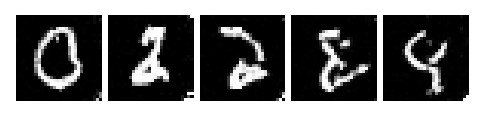

In [157]:
x_imputed_ode = torch.clamp(imputed_images_t_ode_vp[..., -1], 0.0, 1.0)
_ = plot_image_grid(
    images=x_imputed_ode,
    figsize=(6, 6),
    n_rows=1,
    n_cols=n_images_smaller,
    normalize=True,
)